In [142]:
#그래프관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression
from sklearn.preprocessing import StandardScaler,PolynomialFeatures,OneHotEncoder     
from sklearn.metrics import mean_absolute_error
from scipy.special import expit



In [143]:
# [ 도미 ] - 35
bream_length = [25.4, 26.3, 26.5, 29.0, 29.0, 29.7, 29.7, 30.0, 30.0, 30.7, 31.0, 31.0, 31.5, 32.0, 32.0, 32.0, 33.0, 33.0,
33.5, 33.5, 34.0, 34.0, 34.5, 35.0, 35.0, 35.0, 35.0, 36.0, 36.0, 37.0, 38.5, 38.5, 39.5, 41.0, 41.0]
bream_weight = [242.0, 290.0, 340.0, 363.0, 430.0, 450.0, 500.0, 390.0, 450.0, 500.0, 475.0, 500.0, 500.0, 340.0, 600.0, 600.0, 700.0, 700.0,
610.0, 650.0, 575.0, 685.0, 620.0, 680.0, 700.0, 725.0, 720.0, 714.0, 850.0, 1000.0, 920.0, 955.0, 925.0, 975.0, 950.0]

# [ 빙어 ] - 14
smelt_length = [9.8, 10.5, 10.6, 11.0, 11.2, 11.3, 11.8, 11.8, 12.0, 12.2, 12.4, 13.0, 14.3, 15.0]
smelt_weight = [6.7, 7.5, 7.0, 9.7, 9.8, 8.7, 10.0, 9.9, 9.8, 12.2, 13.4, 12.2, 19.7, 19.9]

In [144]:
#데이터 전처리
length = bream_length + smelt_length
weight = bream_weight + smelt_weight
data = np.column_stack((length,weight))
label = ['도미']*35 + ['빙어']*14
label = np.array(label)
label





array(['도미', '도미', '도미', '도미', '도미', '도미', '도미', '도미', '도미', '도미', '도미',
       '도미', '도미', '도미', '도미', '도미', '도미', '도미', '도미', '도미', '도미', '도미',
       '도미', '도미', '도미', '도미', '도미', '도미', '도미', '도미', '도미', '도미', '도미',
       '도미', '도미', '빙어', '빙어', '빙어', '빙어', '빙어', '빙어', '빙어', '빙어', '빙어',
       '빙어', '빙어', '빙어', '빙어', '빙어'], dtype='<U2')

In [145]:
#데이터 분리
train_data,test_data,train_label,test_label = train_test_split(data,label,stratify=label,random_state=42)


In [146]:
ss = StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data)

In [147]:
lr = LogisticRegression()
lr.fit(train_scaled,train_label)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [ ]:
new = [[21,90]]
new = [[25,150]]


In [ ]:
# in_data = input('생선의 길이,무게를 입력하세요. 예)21,90')
in_data = '21,90'
in_data = in_data.split(',')
in_data2 = list(map(float,in_data))
in_data2

[21.0, 90.0]

In [155]:
new_scaled = ss.transform([[21,90]])
new2_scaled = ss.transform([[25,150]])

In [165]:
result = lr.predict(new_scaled)
result2 = lr.predict(new2_scaled)
result[0]
p_result = lr.predict_proba(new_scaled)
p_result2 = lr.predict_proba(new2_scaled)
p_result[0][0]
print(f'예측생선 : {result[0]} / ({p_result[0][1]*100:.2f}%)')
print(f'예측생선 : {result2[0]} / ({p_result2[0][0]*100:.2f}%)')

예측생선 : 빙어 / (53.01%)
예측생선 : 도미 / (69.69%)


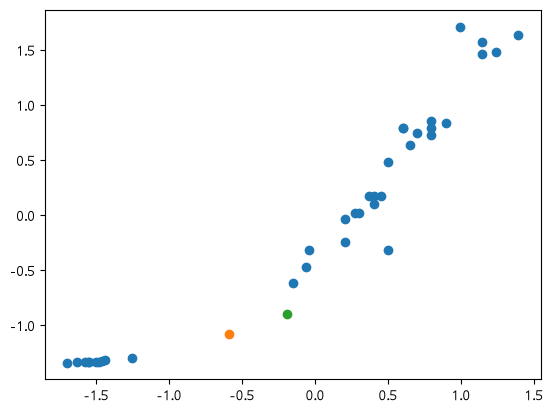

In [174]:
plt.scatter(train_scaled[:,0],train_scaled[:,1])
plt.scatter(new_scaled[:,0],new_scaled[:,1])
plt.scatter(new2_scaled[:,0],new2_scaled[:,1])
plt.show()

In [148]:
lr.predict_proba(test_scaled[:5])

array([[0.99234088, 0.00765912],
       [0.98746689, 0.01253311],
       [0.99890692, 0.00109308],
       [0.18644417, 0.81355583],
       [0.13431246, 0.86568754]])

In [149]:
decisions = lr.decision_function(test_scaled[:5])
np.round(decisions,decimals=4)
expit(decisions)

array([0.00765912, 0.01253311, 0.00109308, 0.81355583, 0.86568754])

In [150]:
bream_smelt_index = (train_label == '도미') | (train_label == '빙어')
train_bream_smelt = train_scaled[bream_smelt_index]
label_bream_smelt = train_label[bream_smelt_index]

In [151]:
lr.classes_

array(['도미', '빙어'], dtype='<U2')

In [152]:
print('분류 : ',lr.predict(train_bream_smelt[:5]))
print(lr.classes_)
print(lr.predict_proba(train_bream_smelt[:5]))

분류 :  ['도미' '도미' '빙어' '도미' '빙어']
['도미' '빙어']
[[0.99219203 0.00780797]
 [0.91522599 0.08477401]
 [0.10127808 0.89872192]
 [0.96146335 0.03853665]
 [0.10003406 0.89996594]]


In [175]:
print('train정확도 : ',lr.score(train_scaled,train_label))
print('test정확도 : ',lr.score(test_scaled,test_label))

train정확도 :  1.0
test정확도 :  1.0
